In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

df = pd.read_csv("../data/processed/featured_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (100000, 26)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,revol_bal,revol_util,total_acc,application_type,mort_acc,pub_rec_bankruptcies,fico_avg,income_to_loan,installment_to_income,default
0,23000.0,36,6.24,702.21,A,A2,1.0,RENT,150000.0,Source Verified,...,26479.0,37.2,31.0,Individual,0.0,0.0,717.0,6.521739,0.056177,0
1,10000.0,60,18.25,255.30,E,E1,0.0,RENT,53000.0,Source Verified,...,4784.0,52.0,18.0,Individual,0.0,0.0,662.0,5.300000,0.057804,1
2,25000.0,36,7.99,783.30,A,A5,3.0,MORTGAGE,140000.0,Source Verified,...,53593.0,15.9,16.0,Individual,2.0,0.0,767.0,5.600000,0.067140,0
3,5600.0,36,7.99,175.46,A,A4,10.0,RENT,45000.0,Not Verified,...,4105.0,20.4,16.0,Individual,0.0,0.0,687.0,8.035714,0.046789,1
4,17450.0,36,14.99,604.83,C,C4,10.0,RENT,48000.0,Verified,...,6554.0,72.8,17.0,Individual,0.0,0.0,667.0,2.750716,0.151207,0


In [2]:
if "default" not in df.columns:
    raise ValueError("Target column 'default' is missing.")

# Remove rows with missing target values
df = df.dropna(subset=["default"]).copy()

# Separate target and features
y = df["default"].astype(int)

X = df.drop(
    columns=["default", "loan_status"],
    errors="ignore"
)

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

# Display dataset information
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

X shape: (100000, 25)
y shape: (100000,)

Target distribution:
default
0    79869
1    20131
Name: count, dtype: int64

Target proportions:
default
0    0.79869
1    0.20131
Name: proportion, dtype: float64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (80000, 25)
Testing features: (20000, 25)

Training target distribution:
default
0    0.798687
1    0.201313
Name: proportion, dtype: float64

Testing target distribution:
default
0    0.7987
1    0.2013
Name: proportion, dtype: float64


In [4]:
numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 19
Categorical features: 6


In [5]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [6]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [7]:
def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    print(f"\n{model_name}")
    print("-" * len(model_name))
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions))

    return results


logistic_results = evaluate_model(
    logistic_model,
    X_test,
    y_test,
    "Logistic Regression"
)

rf_results = evaluate_model(
    random_forest_model,
    X_test,
    y_test,
    "Random Forest"
)


Logistic Regression
-------------------
              precision    recall  f1-score   support

           0       0.89      0.62      0.73     15974
           1       0.31      0.68      0.43      4026

    accuracy                           0.63     20000
   macro avg       0.60      0.65      0.58     20000
weighted avg       0.77      0.63      0.67     20000

Confusion matrix:
[[9869 6105]
 [1275 2751]]

Random Forest
-------------
              precision    recall  f1-score   support

           0       0.81      0.99      0.89     15974
           1       0.51      0.05      0.09      4026

    accuracy                           0.80     20000
   macro avg       0.66      0.52      0.49     20000
weighted avg       0.75      0.80      0.73     20000

Confusion matrix:
[[15779   195]
 [ 3819   207]]


In [8]:
results_df = pd.DataFrame(
    [logistic_results, rf_results]
)

results_df = results_df.set_index("Model")

print(results_df.round(4))

results_df.to_csv(
    "../data/processed/model_comparison.csv"
)

                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Model                                                              
Logistic Regression    0.6310     0.3106  0.6833    0.4271   0.7071
Random Forest          0.7993     0.5149  0.0514    0.0935   0.6920


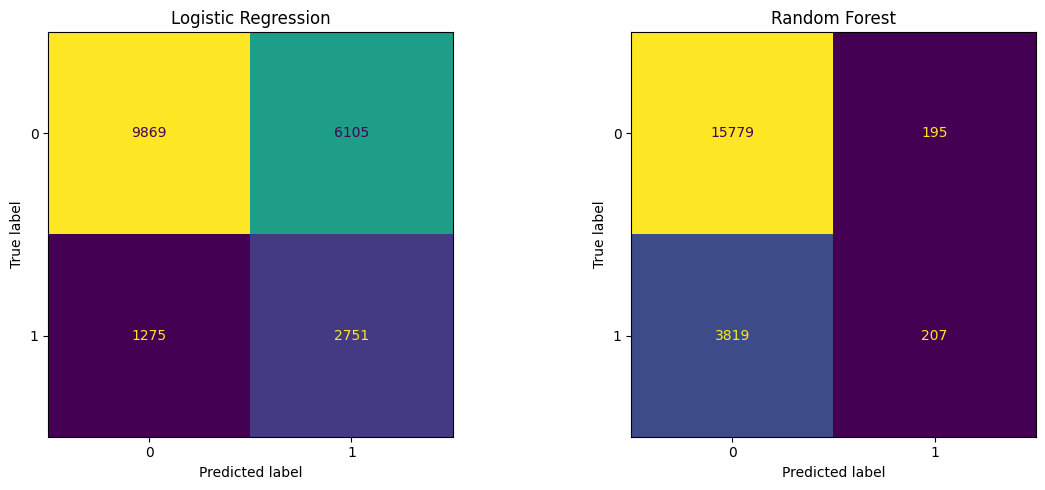

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_estimator(
    random_forest_model,
    X_test,
    y_test,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

In [10]:
best_model_name = results_df["F1-score"].idxmax()

print("Model with the highest F1-score:", best_model_name)

if best_model_name == "Logistic Regression":
    best_model = logistic_model
else:
    best_model = random_forest_model

print("Selected model:", best_model_name)

Model with the highest F1-score: Logistic Regression
Selected model: Logistic Regression


In [11]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd

# Split the existing training set into fitting and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a separate Logistic Regression model for threshold selection
lr_validation_model = clone(logistic_model)
lr_validation_model.fit(X_fit, y_fit)

# Get predicted default probabilities on validation data
val_probabilities = lr_validation_model.predict_proba(X_val)[:, 1]

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

# Prefer the highest precision among thresholds achieving >= 80% recall
target_recall = 0.80
eligible = np.where(recall[:-1] >= target_recall)[0]

if len(eligible) > 0:
    best_idx = eligible[
        np.argmax(precision[eligible])
    ]
    selected_threshold = thresholds[best_idx]
    print("Selected threshold:", round(selected_threshold, 4))
    print("Validation precision:", round(precision[best_idx], 4))
    print("Validation recall:", round(recall[best_idx], 4))
else:
    # Fallback if no threshold achieves the target recall
    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )
    best_idx = np.argmax(f1_scores)
    selected_threshold = thresholds[best_idx]

    print("Target recall not achieved; selected threshold by F1.")
    print("Selected threshold:", round(selected_threshold, 4))
    print("Validation precision:", round(precision[best_idx], 4))
    print("Validation recall:", round(recall[best_idx], 4))

Selected threshold: 0.4314
Validation precision: 0.2832
Validation recall: 0.8001


In [12]:
# Use the existing Logistic Regression model fitted on all X_train
test_probabilities = logistic_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("Selected threshold:", round(selected_threshold, 4))
print("\nTest classification report:")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))

print("Test confusion matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nTest metrics:")
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, test_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, test_predictions, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, test_predictions, zero_division=0), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

Selected threshold: 0.4314

Test classification report:
              precision    recall  f1-score   support

           0       0.91      0.49      0.64     15974
           1       0.28      0.80      0.42      4026

    accuracy                           0.55     20000
   macro avg       0.59      0.64      0.53     20000
weighted avg       0.78      0.55      0.59     20000

Test confusion matrix:
[[7807 8167]
 [ 802 3224]]

Test metrics:
Accuracy: 0.5515
Precision: 0.283
Recall: 0.8008
F1-score: 0.4182
ROC-AUC: 0.7071
